# 00 · Questions, contracts and research design

How can an engine distinguish a price discrepancy, a model-based expected return, and a payoff that is positive in every admissible state? These are separate questions. The project studies recurring New York, Chicago and Miami temperature contracts, using free REST access and a deliberately narrow, auditable event universe.

As Wolfers and Zitzewitz (2006) explain in *Interpreting prediction market prices as probabilities*, the probability interpretation of a contract price depends on market assumptions. Consequently the model uses a market-derived probability baseline, not an assertion that each quoted cent is the true event probability.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'kalshi_engine/client.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from kalshi_engine.client import ROOT
from kalshi_engine.presentation import show_table, show_figure, equation, read
from kalshi_engine.microstructure import Book, FeePolicy, sweep, execution_fee
from kalshi_engine.arbitrage import partition_audit, temperature_payoff_states, coherence, basket, statewise_portfolio
from kalshi_engine.probability import normalise, calibrate, scores, fit_temperature, paired_block_interval
print('Kalshi Microstructure Research | recorded public-data study | no order placement')

Kalshi Microstructure Research | recorded public-data study | no order placement


## Payoffs precede prices

The financial object is the written contract. A short market title is insufficient to infer a payoff identity. The current GLOBALTEMPERATURE terms use full reported precision and permit exceptional fair-value settlement. Six integer-labelled ranges can fail to exhaust a continuous temperature domain. Equations (1), (9) and (10) identify the relevant distinction.

In [2]:
equation(1)
equation(9)
equation(10)
audit = pd.read_csv(ROOT/'outputs/tables/contract-audit.csv')
show_table(audit.groupby('series')[['integer_partition','full_precision_exhaustive','exceptional']].sum().reset_index(), 'Table N00.1. Contract audits across historical and live event groups.')
assert audit.integer_partition.all()
assert not audit.full_precision_exhaustive.any()
print('Normal integer-resolution comparisons are conditional; continuous-state gaps are retained.')

X_i(\omega)=\mathbf{1}\{\omega\in A_i\},\qquad X_i^{N}(\omega)=1-X_i(\omega) (1)

\sum_i b_i^Y\leq1\leq\sum_i a_i^Y (9)

\Pi(\omega;\mathbf q)=\sum_i X_i(\omega)q_i-\sum_i[C_i(q_i)+F_i(q_i)] (10)

series,integer_partition,full_precision_exhaustive,exceptional
KXHIGHCHI,92,0,46
KXHIGHMIA,92,0,46
KXHIGHNY,92,0,46


Normal integer-resolution comparisons are conditional; continuous-state gaps are retained.


## Chronological evaluation

The design sets 19 July–10 September 2026 for development, 11–28 September for validation, and 29 September–16 October for testing. All cities and all contracts on a date stay in the same phase. Noon local time is the primary observation; 09:00 and 15:00 are sensitivity views. The original protocol and amendment are retained. This is retrospective acquisition with a chronological held-out comparison, not a prospective trading trial.

phase,status,events
development,accepted,162
test,accepted,53
test,missing_exact_completed_hour,1
validation,accepted,53
validation,missing_exact_completed_hour,1


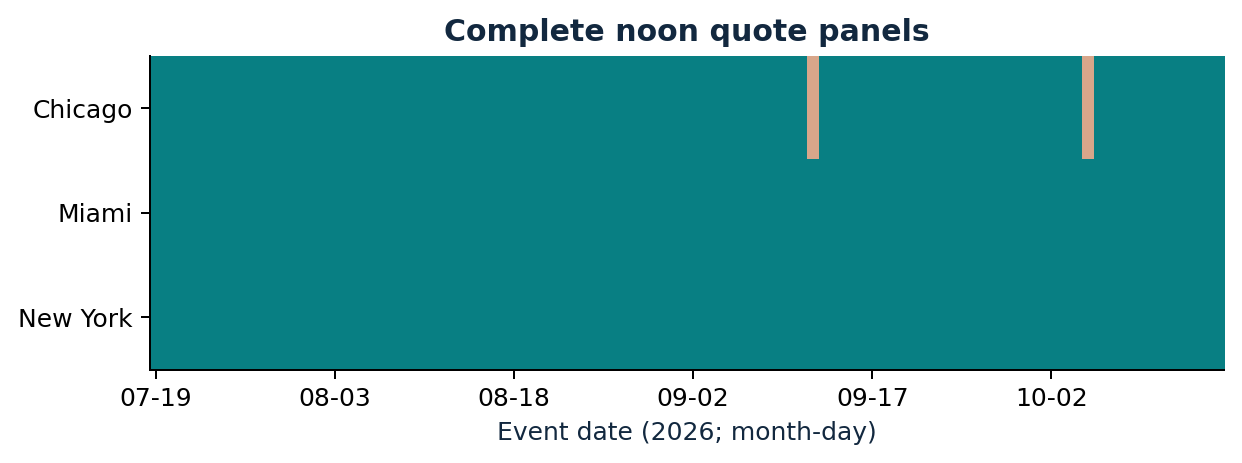

Figure 1. Coverage of complete six-contract panels at 12:00 local time; peach indicates an excluded event.

Protocol: 01_research_design.md
Amendment: A01_api_and_contract_audit.md


In [3]:
coverage = pd.read_csv(ROOT/'outputs/tables/coverage.csv')
show_table(coverage[coverage.hour==12].groupby(['phase','status']).size().reset_index(name='events'), 'Table N00.2. Primary noon event coverage by sample.')
show_figure(1)
print('Protocol:', (ROOT/'protocol/01_research_design.md').name)
print('Amendment: A01_api_and_contract_audit.md')

## Milestone outcome

The research questions, payoff assumptions, observation clock, evaluation split and publication sequence are fixed. The research review precedes paper compilation. The final paper retains A4 portrait pages, centred captions, numbered equations and all preliminary lists. Public release of empirical API material is unresolved under the developer agreement; original code and synthetic examples can be prepared independently.